===== MEDICAL IMAGE ANALYSIS =====
Best Threshold: 4
Total Pixels: 10000
Segmented Pixels: 5031
Background Pixels: 4969
Segmented Area: 50.31 %


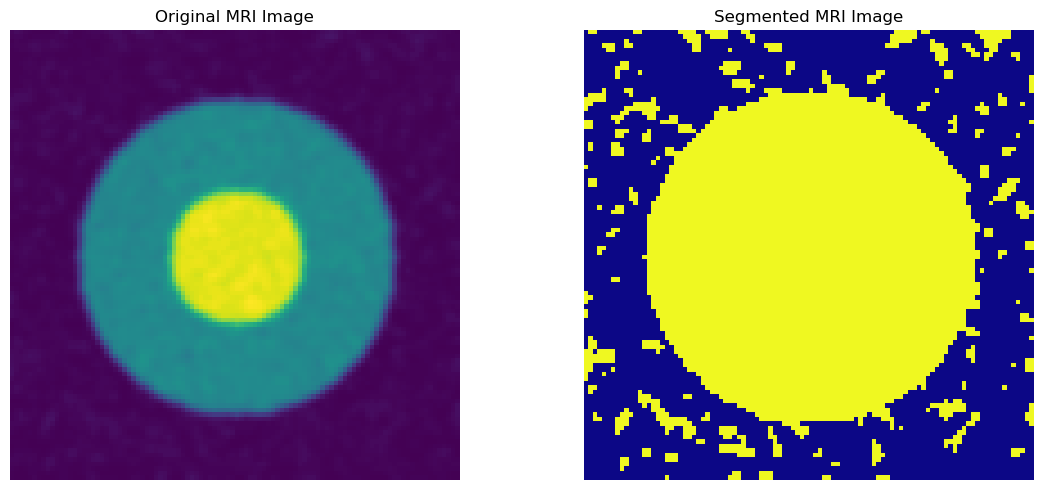

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import gaussian_filter
from concurrent.futures import ThreadPoolExecutor

# 1. Create sample MRI image
image = np.zeros((100, 100), dtype=np.uint8)

Y, X = np.ogrid[:100, :100]

image[(X-50)**2 + (Y-50)**2 <= 35**2] = 100
image[(X-50)**2 + (Y-50)**2 <= 15**2] = 200

# 2. Add noise
noise = np.random.normal(0, 10, (100, 100))
image = np.clip(image + noise, 0, 255).astype(np.uint8)

# 3. Image enhancement
image = gaussian_filter(image, sigma=1)

# 4. Initialize population
population = [random.randint(50, 200) for _ in range(10)]

# 5. Fitness function
def fitness(t):
    return np.sum(image > t)

# 6. Parallel Cellular Algorithm
for generation in range(20):

    with ThreadPoolExecutor() as executor:
        scores = list(executor.map(fitness, population))

    new_population = population.copy()

    for i in range(10):
        left = population[(i-1) % 10]
        right = population[(i+1) % 10]

        best = max([left, population[i], right], key=fitness)

        new_population[i] = max(1, min(254,
            best + random.randint(-5, 5)))

    population = new_population

# 7. Find best threshold
best_threshold = max(population, key=fitness)

# 8. Segment image
segmented = image > best_threshold

# 9. Calculate results
print("===== MEDICAL IMAGE ANALYSIS =====")
print("Best Threshold:", best_threshold)
print("Total Pixels:", image.size)
print("Segmented Pixels:", np.sum(segmented))
print("Background Pixels:", image.size - np.sum(segmented))
print("Segmented Area:", round(np.mean(segmented)*100, 2), "%")

# 10. Display colourful images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='viridis')
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='plasma')
plt.title("Segmented MRI Image")
plt.axis("off")

plt.tight_layout()
plt.show()
